# Proyecto Parte 2 — Clasificación de sentimiento multilingüe con Deep Learning y aumentación de datos

Curso Aprendizaje de Máquina 2026-20 · Universidad de los Andes · Equipo Kaggle: **overfitting survivors**

**Integrantes:**

*Nicolas Valentin - 202222719*

*Juan Manuel Rodríguez Diaz - 202013372*

*Nikol Katherin Rodriguez Ortiz - 202317538*

*Fabio Enrique Higuera Pacanchique - 202215273*


**Modelo entregado.** Los pesos de las corridas originales no se guardaron (por espacio en disco de Kaggle), así que reentrenamos los
mismos 10 modelos con el mismo código y semilla, esta vez guardándolos: OOF **0,913**, envío 07 (sección 12). Pesos (22,6 GB):
[pesos-p2-final-c](https://www.kaggle.com/datasets/nicolasdavidvalentin/pesos-p2-final-c) (5 modelos sin aumentación) y
[pesos-p2-final-d](https://www.kaggle.com/datasets/nicolasdavidvalentin/pesos-p2-final-d) (5 modelos con concatenación).

**Entorno de referencia.** Análisis: Python 3.12 · PyTorch 2.x · transformers 4.56 · scikit-learn 1.7 (ver `requirements.txt`).
Entrenamiento: kernels de Kaggle con GPU NVIDIA T4 (transformers 5.x). Semilla única `SEED = 42`.


## Aporte individual

El proyecto se desarrolló en equipo: los cuatro integrantes participaron en las sesiones de decisión de cada iteración,
en la revisión cruzada del código y en la redacción. Para repartir el trabajo, cada integrante lideró una parte:

| Integrante | Responsabilidad principal | Secciones |
|---|---|---|
| Nicolas Valentin | Análisis exploratorio; heurística de detección de idioma y su validación manual (incluido el diagnóstico de la diferencia de codificación en Kaggle); diseño de la partición hold-out y de los 5 folds; baseline clásico B0 | 3, 4, 5, 6 |
| Juan Manuel Rodríguez Diaz | Diseño, implementación y verificación manual de las tres técnicas de aumentación (ruido, máscara, concatenación); experimentos de la fase A con XLM-R base (E1k–E5) y comparación con/sin aumentación | 7, 9 (fase A), 10 |
| Nikol Katherin Rodriguez Ortiz | Pipeline de fine-tuning (`src/p2_train.py`); infraestructura de entrenamiento en GPU de Kaggle (`kaggle_run.py`, `kaggle_pull.py`); detección y corrección del error de predicciones desalineadas; XLM-R large y validaciones cruzadas (fases C y D); registro de experimentos y envíos a Kaggle | 8, 9 (fases B–E), 12 |
| Fabio Enrique Higuera Pacanchique | Análisis de errores por idioma y estimación del techo de desempeño; diseño del ensamble final; intento con mDeBERTa; replicabilidad y guardado del modelo; referencias y **declaración de uso de IA generativa** (sección 14 y `docs/REFERENCIAS_Y_USO_IA.md`) | 11, 13, 14, 15 |

La documentación de cada sección la escribió quien la lideró y la revisaron los demás.

## 1. Introducción

**Problema.** Dada una reseña de producto, predecir si la opinión global es `negativo`, `neutral` o `positivo` (métrica: *accuracy*).
Frente a la Parte 1 (reseñas en español, mejor modelo clásico 0,909 en Kaggle), el problema cambia en dos frentes:

1. **Las reseñas son multilingües** —español, inglés, portugués, francés y mezclas español-inglés— y el idioma no viene indicado.
2. **El sentimiento es más indirecto**: muchas reseñas combinan elogios y quejas, y el veredicto depende del orden, de las negaciones
   y de los conectores contrastivos ("la batería es excelente, *pero*…"). Una bolsa de palabras pierde ese orden.

**Por qué aprendizaje profundo.** Un *encoder* Transformer procesa la secuencia completa: cada palabra obtiene una representación que
depende de las demás (embeddings contextuales), de modo que "excelente" no aporta lo mismo antes o después de un "pero". Además, un
encoder preentrenado en 100 idiomas comparte un espacio de representación entre idiomas, lo que permite aprovechar en portugués o
francés lo aprendido con las reseñas en español (transferencia de aprendizaje).

**Enfoque.**
- Fine-tuning de encoders multilingües preentrenados (**XLM-RoBERTa base y large**) con una cabeza de clasificación, comparados con un
  baseline clásico (TF-IDF + regresión logística) sobre **la misma partición**.
- Tres estrategias de **aumentación de datos sin modelos generativos** (ruido léxico, enmascarado, concatenación de reseñas), medidas
  con y sin aumentación sobre la misma validación.
- **Validación cruzada de 5 particiones** para estimar el desempeño sobre todo `train` y para construir el ensamble final.
- Análisis de errores por idioma y estimación del techo de desempeño alcanzable.

**Reglas que se respetan en todo el documento** (enunciado y aclaración del profesor):
- Solo arquitecturas *encoder-only* (XLM-RoBERTa; mDeBERTa en un intento fallido) con una cabeza de clasificación. Ningún modelo
  decoder-only ni generativo, tampoco para aumentar datos (descartamos retrotraducción y paráfrasis).
- `eval.csv` solo se usa para predecir; nunca para entrenar, validar ni ajustar hiperparámetros.
- La aumentación se aplica únicamente a la parte de entrenamiento de cada partición; la validación nunca contiene datos sintéticos.
- No se usaron datos externos.

**Cómo está organizado el código.** Toda la lógica vive en `src/p2_train.py`, cuyas secciones están embebidas aquí tal cual. El notebook
tiene dos modos:
- `MODO = "analisis"` (por defecto): no entrena; lee las salidas guardadas en `salidas/` (métricas, logits, predicciones) y produce todas
  las tablas y gráficos. Corre en CPU en pocos minutos.
- `MODO = "entrenar"`: ejecuta los experimentos de `A_EJECUTAR` (requiere GPU; 20–140 min por experimento en una T4). Los
  experimentos del proyecto se ejecutaron así en kernels de Kaggle con `src/kaggle_run.py`.

## 2. Setup

In [1]:
MODO = "analisis"          # "analisis" | "entrenar"
A_EJECUTAR = ["E1k_xlmrb_sin_aug"]   # experimentos a correr si MODO == "entrenar"

import os, re, json, random, time, sys
from pathlib import Path
import numpy as np, pandas as pd
import torch
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score

SEED = 42
LABELS = ["negativo", "neutral", "positivo"]
L2I = {l: i for i, l in enumerate(LABELS)}; I2L = {i: l for l, i in L2I.items()}
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
from scipy.special import softmax
from scipy.stats import binomtest
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=0.95)
pd.set_option("display.max_colwidth", 400)

In [2]:
def rutas():
    if Path("/kaggle/input").exists():
        cands = sorted(Path("/kaggle/input").rglob("train.csv"))   # p.ej. /kaggle/input/competitions/<slug>/train.csv
        return cands[0].parent, Path("/kaggle/working")
    base = Path(__file__).resolve().parent.parent if "__file__" in globals() else Path(".")
    return base / "data", base / "salidas"

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

DATA, OUT = (Path("data"), Path("salidas")) if Path("data/train.csv").exists() else rutas()
OUT.mkdir(exist_ok=True, parents=True)
print("datos:", DATA, "| salidas:", OUT, "| GPU:", torch.cuda.is_available())

datos: data | salidas: salidas | GPU: False


## 3. Carga de datos y análisis exploratorio

Comprobamos tamaño, balance de clases, longitud de los textos y la relación con los datos de la Parte 1. La longitud fija `max_len` del
tokenizador; el balance decide si hace falta ponderar clases.

train: (20466, 3) | eval: (6781, 2) | duplicados en train: 0 | textos de eval presentes en train: 0


label,positivo,negativo,neutral
proporción,0.366,0.361,0.274


,count,mean,std,min,25%,50%,75%,max
train,20466.0,57.5,14.2,3.0,49.0,57.0,67.0,125.0
eval,6781.0,61.3,14.4,4.0,52.0,61.0,72.0,124.0


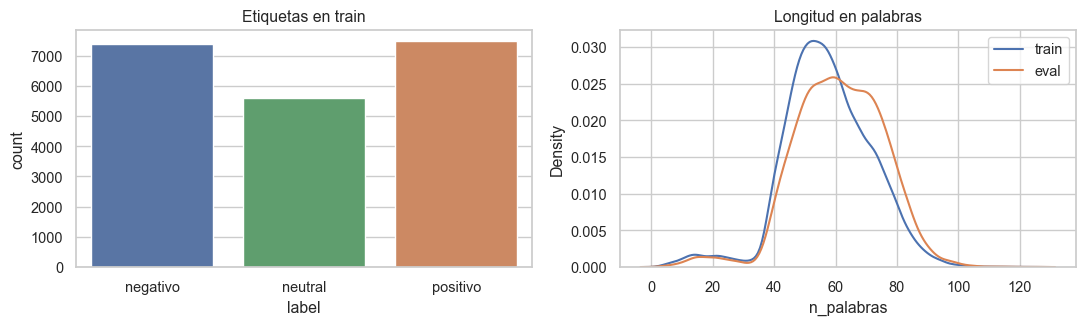

In [3]:
train = pd.read_csv(DATA / "train.csv"); eval_df = pd.read_csv(DATA / "eval.csv"); sample = pd.read_csv(DATA / "sample_submission.csv")
assert set(train.label) == set(LABELS) and len(sample) == len(eval_df)
print(f"train: {train.shape} | eval: {eval_df.shape} | duplicados en train: {train.text.duplicated().sum()} | textos de eval presentes en train: {eval_df.text.isin(set(train.text)).sum()}")
display(train.label.value_counts(normalize=True).round(3).rename("proporción").to_frame().T)
train["n_palabras"] = train.text.str.split().str.len(); eval_df["n_palabras"] = eval_df.text.str.split().str.len()
display(pd.concat([train.n_palabras.describe().rename("train"), eval_df.n_palabras.describe().rename("eval")], axis=1).round(1).T)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
sns.countplot(data=train, x="label", order=LABELS, ax=ax[0], hue="label", legend=False); ax[0].set_title("Etiquetas en train")
sns.kdeplot(train.n_palabras, label="train", ax=ax[1]); sns.kdeplot(eval_df.n_palabras, label="eval", ax=ax[1]); ax[1].legend(); ax[1].set_title("Longitud en palabras")
plt.tight_layout(); plt.show()

In [4]:
# Reseñas nuevas respecto a la Parte 1 (train incluye los 12.000 ejemplos de la Parte 1)
p1 = Path("../proyecto-parte-1-machine-learning/data/train.csv")
if p1.exists():
    train["nueva"] = ~train.text.isin(set(pd.read_csv(p1).text)); print("reseñas nuevas:", train.nueva.sum(), "| heredadas de la Parte 1:", (~train.nueva).sum())
from transformers import AutoTokenizer
tok_xlmr = AutoTokenizer.from_pretrained("xlm-roberta-base")
n_tok = pd.Series([len(x) for x in tok_xlmr(pd.concat([train.text, eval_df.text]).tolist())["input_ids"]])
print(f"tokens XLM-R por texto (train+eval): mediana {n_tok.median():.0f} | p99 {n_tok.quantile(.99):.0f} | máximo {n_tok.max()}")
for _, r in train.sample(4, random_state=7).iterrows(): print(f"[{r.label}] {r.text[:260]}…\n")

reseñas nuevas: 8466 | heredadas de la Parte 1: 12000


tokens XLM-R por texto (train+eval): mediana 79 | p99 129 | máximo 176
[positivo] Lo compré hace poco en una tienda por internet y me llegó en unos cuatro días. Lo uso a diario desde entonces. El ensamblaje no es para nada lo que esperaba, la verdad. La resolución funciona de maravilla. Ni tan bueno ni tan malo.…

[neutral] Lo pedí en una promoción hace un par de semanas y llegó en seis días. La entrega la hizo la transportadora de siempre, la misma que me trae otros paquetes al barrio. Desde entonces lo estoy probando a fondo, casi todos los días en la tarde después del trabajo.…

[positivo] Bought this suitcase in March for the trip to visit my sister, and honestly I was nervous because my old one had been through a lot. The wheels rolled smoothly through the airport, even when I had to run for a connection. My husband borrowed it for his work tr…

[neutral] Lo compré hace un par de meses por internet y me llegó en unos cuatro días. Después de usarlo bastante, lo estoy probando a fon

**Observaciones.**
- **Clases razonablemente balanceadas** (≈37 % positivo, 36 % negativo, 27 % neutral): la *accuracy* es adecuada y no ponderamos clases.
- **Textos cortos**: mediana de 57 palabras (79 tokens de XLM-R); el más largo de `train` + `eval` tiene 176 tokens, así que `max_len = 192`
  no trunca ningún texto (el modelo siempre ve la reseña completa, incluido el cierre, que suele concentrar el veredicto).
- **Sin fugas**: no hay duplicados en `train` ni textos de `eval` presentes en `train`.
- De los 20.466 ejemplos, 12.000 son los de la Parte 1 (en español) y el resto son reseñas nuevas, en su mayoría en otros idiomas.
- Los textos de `eval` son algo más largos que los de `train` (mediana 61 frente a 57 palabras), y muchas reseñas mezclan elogios y quejas.

## 4. Detección de idioma

El idioma no viene dado y lo necesitamos para (i) estratificar la validación y (ii) analizar los errores por subgrupo. Usamos una
heurística **sin dependencias ni modelos externos**: para cada idioma contamos la fracción de palabras funcionales que son
*exclusivas* de ese idioma (`the`/`and` para inglés, `não`/`você` para portugués, `les`/`avec` para francés). Si español e inglés
aparecen ambos con fuerza, etiquetamos `mix` (code-switching). Las palabras compartidas (`de`, `a`, `no`, `en`…) se descartan
porque confunden es/pt/fr.

**Nota de replicabilidad.** Kaggle ejecutó `p2_train.py` leyéndolo como latin-1 (en sus logs aparece "versiÃ³n"), de modo que allí las
letras con tilde de la heurística no coincidían con nada. Lo diagnosticamos al ver que la partición de Kaggle no coincidía con la local.
Para que este notebook reproduzca **exactamente** las particiones y métricas de los experimentos, la heurística usa siempre esa misma
"vista" (`_vista_kaggle`). La celda siguiente cuantifica el efecto frente a la versión ideal.

In [5]:
# Heurística sin dependencias: fracción de palabras funcionales EXCLUSIVAS de cada idioma.
STOP = {
 "es": set("el la los las de del y que en un una es por con para no se su al lo como más pero sus le ya o este sí porque esta entre cuando muy sin sobre también me hasta hay donde desde todo nos todos uno les ni ese eso esto mí antes algunos qué yo otro otras otra él tanto esa estos mucho nada muchos poco ella estar algo mi mis te tu".split()),
 "en": set("the of and to a in is it you that he was for on are with as i his they be at one have this from or had by but some what there we can out other were all your when up how said an each she which do their time if will way about many then them would like so these her long make thing see him two has look more day could go come did my no most".split()),
 "pt": set("o a os as de do da dos das e que em um uma é por com para não se seu sua ao como mais mas foi são ele ela já ou isso muito também só pelo pela até quando mesmo tem tinha você meu minha nos nas foram está estão há".split()),
 "fr": set("le la les de des du et que en un une est pour pas dans qui sur avec au ce il elle je nous vous ils sont mais ou où par plus se son sa ses ne y comme tout très bien fait été être avoir cette ces mon ma mes aussi si".split()),
}
# Compatibilidad con las corridas de Kaggle. Kaggle ejecutó este archivo leyéndolo como latin-1 (en sus logs aparece
# "versiÃ³n"), así que allí las letras con tilde de TOK/STOP/PROTEGIDAS quedaron como pares de caracteres ("á" -> "Ã¡")
# y nunca coincidían. Para reproducir EXACTAMENTE las particiones, la aumentación y las métricas por idioma de esas
# corridas, la heurística usa siempre esa misma "vista". Frente a la versión ideal cambia el idioma de 76 de 20.466
# textos (0,4 %), casi todos portugués/español con muchas tildes. En Kaggle el archivo ya llega así: no se transforma.
_FUENTE_UTF8 = len("á") == 1
def _vista_kaggle(s): return s.encode("utf-8").decode("latin-1") if _FUENTE_UTF8 else s

def _tablas(vista):
    stop = {k: {vista(w) for w in v} for k, v in STOP.items()}
    exc = {k: v - set().union(*(w for kk, w in stop.items() if kk != k)) for k, v in stop.items()}
    return exc, re.compile(vista(r"[a-záéíóúñüàâçèêëîïôûùœãõ']+"), re.I)
EXC, TOK = _tablas(_vista_kaggle)              # la que usa todo el pipeline (= la ejecutada en Kaggle)
EXC_UTF8, TOK_UTF8 = _tablas(lambda s: s)      # la versión ideal, solo para cuantificar la diferencia

def detectar_idioma(t, exc=None, tok=None):
    exc, tok = exc or EXC, tok or TOK
    w = tok.findall(t.lower())
    if not w: return "es"
    sc = {k: sum(x in v for x in w) / len(w) for k, v in exc.items()}
    best = max(sc, key=sc.get)
    if sc[best] == 0: return "es"
    es, en = sc["es"], sc["en"]
    if es > 0.04 and en > 0.04 and min(es, en) / max(es, en) > 0.3: return "mix"   # code-switching es-en
    return best

def detectar_idioma_utf8(t): return detectar_idioma(t, EXC_UTF8, TOK_UTF8)

def acc_por_idioma(df, pred):
    ok = (np.asarray(pred) == df.label.map(L2I).values)
    d = pd.DataFrame({"lang": df.lang.values, "ok": ok})
    out = {f"acc_{k}": round(float(v), 4) for k, v in d.groupby("lang").ok.mean().items()}
    out["acc_global"] = round(float(ok.mean()), 4); return out

In [6]:
train["lang"] = train.text.map(detectar_idioma); eval_df["lang"] = eval_df.text.map(detectar_idioma)
dif = (train.lang != train.text.map(detectar_idioma_utf8))
print(f"textos con idioma distinto entre la heurística ejecutada y la ideal: {dif.sum()} de {len(train)} ({dif.mean():.2%})")
dist = pd.concat([train.lang.value_counts(normalize=True).rename("train"),
                  (train[train.nueva].lang.value_counts(normalize=True).rename("train (solo nuevas)") if "nueva" in train else None),
                  eval_df.lang.value_counts(normalize=True).rename("eval")], axis=1).fillna(0).round(3)
display(dist); display(pd.crosstab(train.lang, train.label, margins=True))
for l in ["en", "pt", "fr", "mix"]:
    print(f"--- {l}:", train[train.lang == l].text.iloc[0][:200])

textos con idioma distinto entre la heurística ejecutada y la ideal: 76 de 20466 (0.37%)


,train,train (solo nuevas),eval
lang,,,
es,0.667,0.199,0.602
en,0.115,0.278,0.137
pt,0.111,0.266,0.134
fr,0.102,0.247,0.119
mix,0.005,0.010,0.008


label,negativo,neutral,positivo,All
lang,,,,
en,776,750,830,2356
es,5048,3572,5029,13649
fr,737,576,779,2092
mix,41,16,46,103
pt,779,685,802,2266
All,7381,5599,7486,20466


--- en: I got it a while back on sale online, it arrived in about four days. It's a charger that works off a USB-C port, none of that old connector stuff. I haven't really used it much yet, just tried it out 
--- pt: Comprei esse teclado mês passado pra trabalhar em casa, chegou em quatro dias numa caixa bem embalada. Conectei na porta USB do meu PC de mesa e comecei a usar direto. Deixei na escrivaninha do quarto
--- fr: Le routeur capte très bien dans toute la maison, le signal passe même à l'étage sans coupure, c'est franchement solide. Par contre l'application de configuration est une vraie galère, tout est mal tra
--- mix: La aspiradora tiene buen suction power en el alfombra, la verdad estoy impressed con eso. Pero el cable es demasiado corto y el noise level is really annoying, me despierta a toda la casa. Some days I


**Observaciones.**
- `train` es ≈67 % español y ≈11 % de cada uno de los otros tres idiomas; `eval` tiene ≈60 % español y ≈13 % de cada otro idioma.
  Un modelo que solo funcione bien en español perdería ≈40 % de `eval`, y `eval` pesa más en los idiomas más difíciles.
- El code-switching (`mix`) es marginal (<1 %).
- La revisión manual de una muestra por idioma confirma que la heurística acierta en los idiomas puros. La diferencia entre la versión
  ejecutada y la ideal afecta a 76 textos (0,4 %): solo cambia el estrato de validación y el análisis por subgrupo, no el entrenamiento.

## 5. Partición de validación

Usamos dos esquemas, ambos **estratificados por (idioma, etiqueta)** y con semilla fija:

- **Hold-out del 15 %** (3.070 textos) para la fase de experimentación (secciones 9–10): todos los experimentos y el baseline usan
  exactamente la misma validación, así que las diferencias entre ellos se deben al cambio introducido y no al azar de la partición.
- **Validación cruzada de 5 particiones** (`StratifiedKFold`) para la fase final: cada modelo se entrena con el 80 % y predice el 20 %
  restante. Uniendo los 5 folds obtenemos una predicción *out-of-fold* (OOF) para **cada uno de los 20.466 textos**, hecha por un modelo
  que no lo vio. Es una estimación del desempeño más estable que el hold-out (≈7 veces más ejemplos) y permite comparar
  configuraciones de forma pareada, texto a texto.

La aumentación se construye **dentro** de cada partición de entrenamiento (`construir_aumentado(tr, …)`), después de separar la validación.

> ⚠️ **`eval.csv` no se usa para entrenar ni para validar**; solo para generar las predicciones que se envían. Tampoco se etiqueta con ningún modelo externo.

In [7]:
def partir(train, cfg):
    """Hold-out 15 % estratificado por (idioma, etiqueta), o fold k de una CV estratificada. Nunca toca eval."""
    strat = train.lang + "_" + train.label
    if cfg.get("folds") and cfg["folds"] > 1:
        skf = StratifiedKFold(cfg["folds"], shuffle=True, random_state=SEED)
        tr_i, va_i = list(skf.split(train, strat))[cfg["fold"]]
        return train.iloc[tr_i].reset_index(drop=True), train.iloc[va_i].reset_index(drop=True)
    tr, va = train_test_split(train, test_size=0.15, random_state=SEED, stratify=strat)
    return tr.reset_index(drop=True), va.reset_index(drop=True)

tr_df, va_df = partir(train, {"folds": 0})
print(f"entrenamiento: {len(tr_df)} | validación: {len(va_df)} | intersección: {len(set(tr_df.id) & set(va_df.id))}")
display(pd.crosstab(va_df.lang, va_df.label, margins=True))
folds = {k: partir(train, {"folds": 5, "fold": k})[1].id for k in range(5)}
print("tamaño de cada fold de validación:", {k: len(v) for k, v in folds.items()}, "| cubren todo train:", len(set().union(*map(set, folds.values()))) == len(train))

entrenamiento: 17396 | validación: 3070 | intersección: 0


label,negativo,neutral,positivo,All
lang,,,,
en,116,113,125,354
es,757,536,754,2047
fr,111,86,117,314
mix,6,2,7,15
pt,117,103,120,340
All,1107,840,1123,3070


tamaño de cada fold de validación: {0: 4094, 1: 4093, 2: 4093, 3: 4093, 4: 4093} | cubren todo train: True


## 6. Baseline clásico de referencia

Reproducimos un baseline del estilo de la Parte 1: TF-IDF de palabras (1-2 gramas) y de caracteres (2-5 gramas) + regresión logística,
entrenado con la **misma partición** (`src/baseline_tfidf.py`). Cuantifica cuánto aporta un encoder profundo frente a una bolsa de
n-gramas en este problema. Fue nuestro primer envío (01).

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, make_union
if MODO == "entrenar" or not (OUT / "metrics_B0_tfidf_logreg.json").exists():
    base = make_pipeline(make_union(TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True, min_df=2),
                                    TfidfVectorizer(analyzer="char_wb", ngram_range=(2,5), sublinear_tf=True, min_df=3)),
                         LogisticRegression(C=5, max_iter=3000)).fit(tr_df.text, tr_df.label.map(L2I))
    res_b0 = acc_por_idioma(va_df, base.predict(va_df.text))
else:
    res_b0 = {k: v for k, v in json.load(open(OUT / "metrics_B0_tfidf_logreg.json")).items() if k.startswith("acc_")}
print("B0 TF-IDF + regresión logística (hold-out):", res_b0)

B0 TF-IDF + regresión logística (hold-out): {'acc_en': 0.6893, 'acc_es': 0.7411, 'acc_fr': 0.6529, 'acc_mix': 0.6, 'acc_pt': 0.6882, 'acc_global': 0.7195}


El baseline clásico se queda en ≈0,72 en validación, lejos del ≈0,91 de la Parte 1: con reseñas multilingües y veredictos que
dependen del orden, los n-gramas no bastan. Es peor en francés, inglés y portugués, idiomas con menos ejemplos que el español.

## 7. Aumentación de datos (sin modelos generativos)

El enunciado exige al menos una estrategia de aumentación y documentar su efecto. Por la aclaración del profesor (solo *encoder-only*;
prohibidos los modelos generativos de texto), **descartamos la retrotraducción y la paráfrasis con modelos seq2seq/LLM**. Diseñamos tres
técnicas que conservan la etiqueta y no usan ningún modelo:

| Técnica | Qué hace | Parámetros | Por qué debería ayudar |
|---|---|---|---|
| `ruido` | Borra palabras al azar e intercambia pares vecinos, **sin tocar negaciones ni conectores contrastivos** (`no`, `pero`, `not`, `but`, `mas`, `pas`…) | p_borrado = 0,10; p_intercambio = 0,05 | Regularización: el modelo no puede depender de una palabra concreta; proteger negaciones y conectores evita invertir el sentimiento |
| `mascara` | Sustituye palabras por el token `<mask>` del encoder (con la misma protección) | p = 0,12 | Imita el preentrenamiento MLM: obliga a usar el contexto en vez de palabras clave |
| `concat` | Une la primera mitad (en oraciones) de una reseña con la segunda mitad de **otra con la misma etiqueta y distinto idioma** | pares al azar | Crea documentos bilingües (code-switching sintético) y más largos, parecidos a los de `eval` |

**Construcción de los datos sintéticos.** `aug_frac` fija cuántos ejemplos se generan por técnica como fracción del conjunto de
entrenamiento (0,5 en E2–E4: +8.698 textos; 0,33 por técnica en E5). Todo es determinista (semilla fija) y se genera **solo** a partir de
la partición de entrenamiento. La etiqueta del texto sintético es la del original (`ruido`, `mascara`) o la etiqueta común de las dos
mitades (`concat`).

In [9]:
# Palabras que NO se tocan: negaciones y conectores contrastivos, porque invierten/organizan el sentimiento.
PROTEGIDAS = set(("no ni nunca jamás tampoco sin pero aunque sino embargo nada nadie "
                  "not never no nor but however although though nothing yet "
                  "não nunca jamais nem mas porém embora contudo nada "
                  "ne pas jamais rien non mais pourtant cependant bien que toutefois").split())
PROTEGIDAS = {_vista_kaggle(w) for w in PROTEGIDAS}   # misma vista que en Kaggle (ver detección de idioma)

def aug_ruido(text, rng, p_del=0.10, p_swap=0.05):
    """Borra palabras al azar e intercambia vecinas, protegiendo negaciones y conectores. Etiqueta inalterada."""
    w = text.split()
    if len(w) < 6: return text
    out = [x for x in w if x.lower().strip(".,;:!?¡¿") in PROTEGIDAS or rng.random() >= p_del]
    for i in range(len(out) - 1):
        if rng.random() < p_swap and out[i].lower() not in PROTEGIDAS and out[i+1].lower() not in PROTEGIDAS:
            out[i], out[i+1] = out[i+1], out[i]
    return " ".join(out) if len(out) >= 4 else text

def aug_mascara(text, rng, mask_token, p=0.12):
    """Sustituye palabras por el token <mask> del encoder (el modelo debe inferirlas del contexto)."""
    w = text.split()
    if len(w) < 6: return text
    return " ".join(mask_token if (x.lower().strip(".,;:!?¡¿") not in PROTEGIDAS and rng.random() < p) else x for x in w)

def aug_concat(df, rng, n, cross_lang=True):
    """Une dos reseñas con la MISMA etiqueta (de idiomas distintos si cross_lang): simula code-switching y
    documentos largos con dos voces. La etiqueta global se conserva porque ambas partes la comparten."""
    rows = []
    por_label = {l: g for l, g in df.groupby("label")}
    for _ in range(n):
        l = rng.choice(LABELS); g = por_label[l]
        a = g.iloc[rng.randrange(len(g))]
        cand = g[g.lang != a.lang] if cross_lang and (g.lang != a.lang).any() else g
        b = cand.iloc[rng.randrange(len(cand))]
        sa = re.split(r"(?<=[.!?])\s+", a.text.strip()); sb = re.split(r"(?<=[.!?])\s+", b.text.strip())
        txt = " ".join(sa[: max(1, len(sa)//2)] + sb[len(sb)//2:])
        rows.append({"text": txt, "label": l})
    return pd.DataFrame(rows)

def construir_aumentado(tr, tecnicas, frac, mask_token, seed=SEED):
    """Genera ejemplos sintéticos SOLO a partir de `tr`. `frac` = proporción de tr que se aumenta por técnica."""
    rng = random.Random(seed); partes = []
    n = int(len(tr) * frac)
    for t in tecnicas:
        if t == "concat":
            d = aug_concat(tr, rng, n)
        else:
            base = tr.sample(n, random_state=seed + len(partes))
            f = (lambda x: aug_ruido(x, rng)) if t == "ruido" else (lambda x: aug_mascara(x, rng, mask_token))
            d = pd.DataFrame({"text": [f(x) for x in base.text], "label": base.label.values})
        d["aug"] = t; partes.append(d)
    if not partes: return tr.iloc[0:0]
    out = pd.concat(partes, ignore_index=True); out["lang"] = out.text.map(detectar_idioma); return out

In [10]:
rng = random.Random(0); ej = tr_df[tr_df.lang == "es"].text.iloc[3]
print("ORIGINAL :", ej[:230]); print("RUIDO    :", aug_ruido(ej, rng)[:230]); print("MÁSCARA  :", aug_mascara(ej, rng, "<mask>")[:230])
c = aug_concat(tr_df, rng, 1).iloc[0]; print(f"CONCAT [{c.label}]:", c.text[:300])
demo = construir_aumentado(tr_df, ["concat"], 0.5, "<mask>")
print("\nEjemplos sintéticos con concat y aug_frac=0.5:", len(demo), "| idiomas detectados:", demo.lang.value_counts().to_dict())

ORIGINAL : Lo compre para el trabajo hace un par de meses, lo uso casi todos los dias en la oficina. Llego en menos de tres dias a mi casa, bien embalado. Despues de usarlo bastante, el empaque me resulto comodo con el uso diario, la verdad.
RUIDO    : Lo compre para el trabajo hace un par de meses, lo uso casi todos los dias en la oficina. Llego en menos de tres dias a mi casa, bien embalado. Despues de usarlo bastante, el empaque resulto comodo con el diario, la verdad. Eso si
MÁSCARA  : Lo compre para el trabajo <mask> <mask> par de meses, lo uso casi <mask> los <mask> en la oficina. Llego en menos <mask> <mask> dias a mi casa, bien embalado. Despues de usarlo bastante, <mask> empaque me resulto comodo con el uso
CONCAT [positivo]: Lo compré hace unos cuatro meses por internet y llegó en tres días, lo uso a diario desde entonces. La construcción me dio más de un dolor de cabeza, la verdad. A instalação foi simples, mas o cabo veio curtinho pra onde eu precisava. Ainda estou me posic


Ejemplos sintéticos con concat y aug_frac=0.5: 8698 | idiomas detectados: {'es': 3208, 'mix': 2001, 'fr': 1635, 'en': 1329, 'pt': 525}


**Verificación manual.** Revisamos 30 ejemplos por técnica: `ruido` y `mascara` mantienen la lectura del sentimiento en todos los casos
revisados gracias a la protección de negaciones y conectores. `concat` produce textos coherentes en etiqueta, aunque a veces cambia de
producto a mitad de texto; es un ruido aceptable, porque el objetivo es que el modelo se acostumbre a cambiar de idioma dentro del
texto y a integrar dos partes con el mismo veredicto.

## 8. Modelo: fundamentos y entrenamiento

### 8.1 Representación del texto

1. **Tokenización en subpalabras.** XLM-RoBERTa usa un modelo SentencePiece (unigram) con un vocabulario de 250.000 piezas compartido por
   100 idiomas. Una palabra rara o con tilde se parte en piezas frecuentes (`decepcionante` → `▁decep`, `cion`, `ante`), así que no existen
   palabras "fuera de vocabulario" y el mismo vocabulario sirve para los cinco idiomas del problema. No hace falta limpiar ni lematizar:
   el tokenizador trabaja sobre el texto original, con mayúsculas, tildes y puntuación, que también aportan señal.
2. **Embeddings de entrada.** Cada pieza se convierte en un vector (768 dimensiones en *base*, 1.024 en *large*) y se le suma un
   **embedding de posición** aprendido. La posición es lo que permite distinguir "bueno pero caro" de "caro pero bueno".
3. **Capas Transformer *encoder*** (12 en *base*, 24 en *large*). Cada capa aplica **auto-atención multi-cabeza** (12 o 16 cabezas): cada
   token calcula pesos de atención sobre todos los demás y se reescribe como combinación de ellos. Después viene una red *feed-forward*,
   con conexiones residuales y normalización de capa. Tras varias capas, la representación de cada token es **contextual**: "excelente"
   tiene un vector distinto si va después de "no" o antes de "pero", que es exactamente lo que una bolsa de palabras no captura.
4. **Preentrenamiento y transferencia.** El encoder viene preentrenado con *masked language modeling* sobre 2,5 TB de texto en 100
   idiomas (CC-100). Ya "sabe" sintaxis, negación y equivalencias entre idiomas; el fine-tuning solo debe aprender el criterio de la tarea.
   Por eso funciona en portugués o francés con pocos miles de ejemplos.

### 8.2 Cabeza de clasificación

Usamos `AutoModelForSequenceClassification`: sobre el estado oculto del token inicial `<s>` (que, por la atención, resume todo el texto)
se aplica *dropout* → capa densa (h×h) + `tanh` → *dropout* → capa lineal (h×3) → *softmax* sobre `negativo`, `neutral` y `positivo`.
La pérdida es la entropía cruzada. Es exactamente la arquitectura "encoder + cabeza de clasificación" que permite la aclaración del
profesor: ningún componente genera texto.

| | XLM-R base | XLM-R large |
|---|---|---|
| Capas / dimensión oculta / cabezas | 12 / 768 / 12 | 24 / 1.024 / 16 |
| Parámetros | ≈279 M | ≈561 M |
| Learning rate | 2·10⁻⁵ | 1·10⁻⁵ |
| Lote efectivo | 16 | 16 (8 × 2 de acumulación de gradiente) |

### 8.3 Entrenamiento y control del sobreajuste

- **Fine-tuning completo** (encoder y cabeza) con AdamW, *weight decay* 0,01, *learning rate* pequeño con calentamiento lineal del 6 %
  y decaimiento lineal. Un LR mayor destruye lo aprendido en el preentrenamiento; *large* necesita uno menor porque es más inestable.
- **Precisión mixta (fp16)** en GPU T4, *padding* dinámico por lote y `max_len = 192` (ningún texto se trunca).
- **Selección de época con validación**: se evalúa al final de cada época, se guarda solo la mejor (`load_best_model_at_end`) y se
  detiene el entrenamiento si la exactitud de validación deja de mejorar (*early stopping*, paciencia 1). Es la principal defensa contra
  el sobreajuste: un modelo de 561 M parámetros memoriza 17.000 textos en pocas épocas, y las curvas de la sección 9 muestran cómo la
  pérdida de validación vuelve a subir tras 2–3 épocas (el modelo se vuelve demasiado confiado) aunque la exactitud aún mejore un poco.
- **Controles de integridad** añadidos tras el error de E1 (sección 9): la exactitud recalculada fila a fila sobre las predicciones
  guardadas debe coincidir con la que reporta el `Trainer`, y en local el modelo se guarda **antes** de predecir.
- Cada experimento guarda los logits de validación y de `eval`, las predicciones de validación con su idioma y el archivo de envío.

In [11]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer,
                          DataCollatorWithPadding, EarlyStoppingCallback, set_seed as hf_seed)
from torch.utils.data import Dataset

class DS(Dataset):
    def __init__(self, df, tok, max_len, con_label=True):
        self.enc = tok(list(df.text), truncation=True, max_length=max_len)
        self.y = df.label.map(L2I).tolist() if con_label else None
    def __len__(self): return len(self.enc["input_ids"])
    def __getitem__(self, i):
        d = {k: v[i] for k, v in self.enc.items()}
        if self.y is not None: d["labels"] = self.y[i]
        return d

# max_len=192: el texto más largo de train/eval tiene 168 tokens XLM-R
CFG_BASE = dict(model="xlm-roberta-base", max_len=192, lr=2e-5, epochs=4, bs=16, grad_acc=1, wd=0.01, warmup=0.06,
                label_smoothing=0.0, aug=[], aug_frac=0.5, seed=SEED, patience=1, save_model=not Path("/kaggle").exists(),
                folds=0, fold=None, fp16=True)          # folds>0 => validación cruzada (fold = índice a entrenar)

def predecir_logits(trainer, tok, df, max_len):
    return trainer.predict(DS(df.assign(label="neutral"), tok, max_len)).predictions

def entrenar(nombre, cfg, train, eval_df, out_dir):
    cfg = {**CFG_BASE, **cfg}; set_seed(cfg["seed"]); hf_seed(cfg["seed"])
    tr, va = partir(train, cfg)
    tok = AutoTokenizer.from_pretrained(cfg["model"])
    aug = construir_aumentado(tr, cfg["aug"], cfg["aug_frac"], tok.mask_token or "[MASK]", cfg["seed"])
    tr_x = pd.concat([tr, aug], ignore_index=True).sample(frac=1, random_state=cfg["seed"]) if len(aug) else tr
    print(f"\n=== {nombre} | {cfg['model']} | train={len(tr)} (+{len(aug)} aug) val={len(va)} | aug={cfg['aug']} ===", flush=True)
    model = AutoModelForSequenceClassification.from_pretrained(cfg["model"], num_labels=3, id2label=I2L, label2id=L2I)
    targs = dict(
        output_dir=str(out_dir / "ckpt" / nombre), learning_rate=cfg["lr"], num_train_epochs=cfg["epochs"],
        per_device_train_batch_size=cfg["bs"], per_device_eval_batch_size=64, gradient_accumulation_steps=cfg["grad_acc"],
        weight_decay=cfg["wd"], warmup_ratio=cfg["warmup"], label_smoothing_factor=cfg["label_smoothing"],
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1, save_only_model=True, load_best_model_at_end=True,
        metric_for_best_model="accuracy", greater_is_better=True, fp16=cfg["fp16"] and torch.cuda.is_available(),
        seed=cfg["seed"], data_seed=cfg["seed"], report_to="none", logging_steps=100,
        dataloader_num_workers=2 if torch.cuda.is_available() else 0)   # workers>0 cuelga en Windows/CPU
    # Sin group_by_length: en transformers 4.56 reordenaba también predict() (predicciones desalineadas)
    # y en transformers 5.x (Kaggle) ya no existe. Se filtran argumentos que la versión instalada no acepte.
    import inspect, math; validos = set(inspect.signature(TrainingArguments.__init__).parameters)
    if "warmup_ratio" not in validos:   # transformers 5 quitó warmup_ratio: se pasa como número de pasos
        pasos = math.ceil(len(tr_x) / (cfg["bs"] * cfg["grad_acc"])) * cfg["epochs"]
        targs["warmup_steps"] = int(cfg["warmup"] * pasos)
    for k in [k for k in targs if k not in validos]:
        print(f"[aviso] TrainingArguments no acepta '{k}' en esta versión; se omite", flush=True); targs.pop(k)
    args = TrainingArguments(**targs)
    trn = Trainer(model=model, args=args, train_dataset=DS(tr_x, tok, cfg["max_len"]), eval_dataset=DS(va, tok, cfg["max_len"]),
                  data_collator=DataCollatorWithPadding(tok),
                  compute_metrics=lambda p: {"accuracy": accuracy_score(p.label_ids, p.predictions.argmax(-1))},
                  callbacks=[EarlyStoppingCallback(early_stopping_patience=cfg["patience"])])
    t0 = time.time(); trn.train()
    hist = [{"epoch": h["epoch"], "acc_val": round(h["eval_accuracy"], 4), "loss_val": round(h["eval_loss"], 4)}
            for h in trn.state.log_history if "eval_accuracy" in h]
    if cfg["save_model"]:   # se guarda ANTES de predecir: si algo falla después no se pierden horas de entrenamiento
        trn.save_model(str(out_dir / "modelos" / nombre)); tok.save_pretrained(str(out_dir / "modelos" / nombre))
    lg_va = trn.predict(DS(va, tok, cfg["max_len"])).predictions
    res = acc_por_idioma(va, lg_va.argmax(-1))
    best = max((h["acc_val"] for h in hist), default=None)
    if best is not None and abs(res["acc_global"] - best) > 0.01:
        raise RuntimeError(f"Predicciones desalineadas: acc post-hoc {res['acc_global']} vs Trainer {best}")
    lg_ev = predecir_logits(trn, tok, eval_df, cfg["max_len"])
    # ---- salidas
    np.save(out_dir / f"val_logits_{nombre}.npy", lg_va); np.save(out_dir / f"eval_logits_{nombre}.npy", lg_ev)
    va.assign(pred=[I2L[i] for i in lg_va.argmax(-1)])[["id", "lang", "label", "pred"]].to_csv(out_dir / f"val_pred_{nombre}.csv", index=False)
    sub = pd.DataFrame({"id": eval_df.id, "answer": [I2L[i] for i in lg_ev.argmax(-1)]}); sub.to_csv(out_dir / f"submission_{nombre}.csv", index=False)
    met = {"exp": nombre, "modelo": cfg["model"], "aug": "+".join(cfg["aug"]) or "ninguna", "aug_frac": cfg["aug_frac"], "n_train": len(tr_x),
           "lr": cfg["lr"], "epochs_max": cfg["epochs"], "bs": cfg["bs"] * cfg["grad_acc"], "max_len": cfg["max_len"], "label_smoothing": cfg["label_smoothing"],
           "seed": cfg["seed"], "folds": cfg["folds"], "fold": cfg["fold"], "mejor_epoca": max(hist, key=lambda h: h["acc_val"])["epoch"] if hist else None,
           "historial": hist, "minutos": round((time.time() - t0) / 60, 1), **res}
    json.dump(met, open(out_dir / f"metrics_{nombre}.json", "w"), indent=1)
    print(json.dumps({k: v for k, v in met.items() if k != "historial"}), flush=True)
    import shutil; shutil.rmtree(out_dir / "ckpt" / nombre, ignore_errors=True)
    del trn, model; torch.cuda.empty_cache()
    return met

In [12]:
EXPERIMENTOS = {
    # --- Fase A: hold-out, XLM-R base. Cada uno cambia UNA cosa respecto a E1.
    "E1_xlmrb_sin_aug":   dict(),
    "E1b_xlmrb_1ep":      dict(epochs=1),          # E1 tuvo su mejor época en la 1; versión barata para CPU local
    # E1k: E1 re-ejecutado en Kaggle con la configuración EXACTA de E2-E5 (misma partición, sin warmup, 4 épocas,
    # early stopping) -> referencia "sin aumentación" pareada para la comparación con/sin aumentación de la sección 10.
    "E1k_xlmrb_sin_aug":  dict(warmup=0.0),
    "E2_xlmrb_ruido":     dict(aug=["ruido"]),
    "E3_xlmrb_mascara":   dict(aug=["mascara"]),
    "E4_xlmrb_concat":    dict(aug=["concat"]),
    "E5_xlmrb_combo":     dict(aug=["ruido", "mascara", "concat"], aug_frac=0.33),
    # --- Fase B: otros encoders con la mejor aumentación (se ajusta tras la fase A)
    "E6_mdeberta_combo":  dict(model="microsoft/mdeberta-v3-base", aug=["ruido", "mascara", "concat"], aug_frac=0.33, lr=2e-5, epochs=5),
    "E7_xlmrl_combo":     dict(model="xlm-roberta-large", aug=["ruido", "mascara", "concat"], aug_frac=0.33, lr=1e-5, epochs=4, bs=8, grad_acc=2),
    "E7b_xlmrl_sin_aug":  dict(model="xlm-roberta-large", lr=1e-5, epochs=4, bs=8, grad_acc=2),
}
# Fase C: validación cruzada 5-fold de XLM-R large (sin aumentación hasta ver la fase A). Cada fold entrena con 80 %
# de train y valida en el 20 % restante → la media de los 5 folds estima el rendimiento sin tocar eval; el envío
# promedia los logits de eval de los 5 modelos (ensamble).
for k in range(5):
    EXPERIMENTOS[f"CV_xlmrl_f{k}"] = dict(model="xlm-roberta-large", lr=1e-5, epochs=5, bs=8, grad_acc=2, folds=5, fold=k)# Fase D: misma CV pero con la aumentación ganadora de la fase A (concatenación: 0.890 -> 0.909 en XLM-R base).
# Mismos folds (StratifiedKFold con SEED fijo) -> las predicciones out-of-fold de C y D son comparables y ensamblables.
for k in range(5):
    EXPERIMENTOS[f"CVc_xlmrl_f{k}"] = dict(model="xlm-roberta-large", aug=["concat"], lr=1e-5, epochs=5, bs=8, grad_acc=2, folds=5, fold=k)
# Fase E: diversidad de arquitectura para el ensamble. mDeBERTa-v3 (encoder-only) con los mismos folds.
# fp16=False: DeBERTa-v3 produce NaN en media precisión. patience=2: en C/D varios folds pararon en la época 1-2.
for k in range(5):
    EXPERIMENTOS[f"CVd_mdeberta_f{k}"] = dict(model="microsoft/mdeberta-v3-base", lr=2e-5, epochs=5, bs=16, patience=2, fp16=False, folds=5, fold=k)

RUN = A_EJECUTAR      # <- lista de experimentos que ejecuta este kernel

if MODO == "entrenar":
    for nombre in A_EJECUTAR:
        entrenar(nombre, EXPERIMENTOS[nombre], train, eval_df, OUT)

## 9. Experimentos: evidencia de iteración

Cada experimento cambia **una sola cosa** respecto a su referencia para poder atribuir la mejora:

- **Fase A** (XLM-R base, hold-out): sin aumentación (E1k) frente a cada técnica por separado (E2–E4) y combinadas (E5).
- **Fase B** (hold-out): XLM-R large sin aumentación (E7b) y primer ensamble.
- **Fase C** (validación cruzada de 5 folds): XLM-R large sin aumentación → OOF sobre los 20.466 textos y 5 modelos para ensamblar.
- **Fase D** (mismos 5 folds): XLM-R large con aumentación por concatenación → comparación pareada con C y ensamble de 10 modelos.
- **Fase E** (mismos 5 folds): mDeBERTa-v3 para diversificar el ensamble (falló; ver más abajo).

La tabla se construye a partir de `salidas/metrics_*.json`. La columna `estado` marca los experimentos que no son válidos y por qué.

In [13]:
ESTADO = {"E1_xlmrb_sin_aug": "inválido: predicciones desalineadas (error de orden en predict)",
          "E1b_xlmrb_1ep": "válido, pero en una partición local distinta (no comparable)"}
def cargar_registro():
    filas = []
    for f in sorted(OUT.glob("metrics_*.json")):
        m = json.load(open(f)); m["historial"] = json.dumps(m.get("historial", [])); filas.append(m)
    df = pd.DataFrame(filas)
    orden = {e: i for i, e in enumerate(["B0_tfidf_logreg"] + list(EXPERIMENTOS))}
    df["estado"] = [ESTADO.get(e, "falló: pérdida NaN (no aprendió)" if e.startswith("CVd_") else
                               "válido (reentrenamiento con pesos guardados)" if e.startswith(("CVr_", "CVcr_")) else "válido") for e in df.exp]
    df["fase"] = ["C" if e.startswith("CV_") else "D" if e.startswith("CVc_") else "E" if e.startswith("CVd_") else
                  "F" if e.startswith(("CVr_", "CVcr_")) else "B0" if e.startswith("B0") else "B" if e.startswith("E7") else "A" for e in df.exp]
    return df.assign(_o=df.exp.map(orden)).sort_values("_o").drop(columns="_o").reset_index(drop=True)
reg = cargar_registro()
cols = ["fase", "exp", "modelo", "aug", "n_train", "lr", "mejor_epoca", "minutos", "acc_global", "acc_es", "acc_en", "acc_pt", "acc_fr", "estado"]
display(reg[[c for c in cols if c in reg.columns]].style.format(precision=4, na_rep="")
        .background_gradient(subset=["acc_global", "acc_es", "acc_en", "acc_pt", "acc_fr"], cmap="Greens", vmin=0.6, vmax=0.95))

,fase,exp,modelo,aug,n_train,lr,mejor_epoca,minutos,acc_global,acc_es,acc_en,acc_pt,acc_fr,estado
0,B0,B0_tfidf_logreg,tfidf(word1-2+char2-5)+logreg,ninguna,17396,,,0.3000,0.7195,0.7411,0.6893,0.6882,0.6529,válido
1,A,E1_xlmrb_sin_aug,xlm-roberta-base,ninguna,17396,0.0000,1.0000,496.1000,0.3524,0.3557,0.3835,0.2911,0.3587,inválido: predicciones desalineadas (error de orden en predict)
2,A,E1b_xlmrb_1ep,xlm-roberta-base,ninguna,17396,0.0000,1.0000,63.8000,0.8899,0.9041,0.8636,0.8847,0.8540,"válido, pero en una partición local distinta (no comparable)"
3,A,E1k_xlmrb_sin_aug,xlm-roberta-base,ninguna,17396,0.0000,2.0000,18.6000,0.9003,0.9155,0.8672,0.8882,0.8567,válido
4,A,E2_xlmrb_ruido,xlm-roberta-base,ruido,26094,0.0000,1.0000,17.1000,0.9013,0.9077,0.8870,0.9235,0.8599,válido
5,A,E3_xlmrb_mascara,xlm-roberta-base,mascara,26094,0.0000,4.0000,33.7000,0.9072,0.9179,0.8701,0.9176,0.8726,válido
6,A,E4_xlmrb_concat,xlm-roberta-base,concat,26094,0.0000,4.0000,34.0000,0.9094,0.9179,0.8870,0.9088,0.8822,válido
7,A,E5_xlmrb_combo,xlm-roberta-base,ruido+mascara+concat,34616,0.0000,1.0000,22.3000,0.9042,0.9145,0.8927,0.9118,0.8535,válido
8,B,E7b_xlmrl_sin_aug,xlm-roberta-large,ninguna,17396,0.0000,4.0000,86.8000,0.9114,0.9170,0.8842,0.9235,0.9013,válido
9,C,CV_xlmrl_f0,xlm-roberta-large,ninguna,16372,0.0000,4.0000,102.1000,0.9152,0.9176,0.9130,0.9139,0.9093,válido


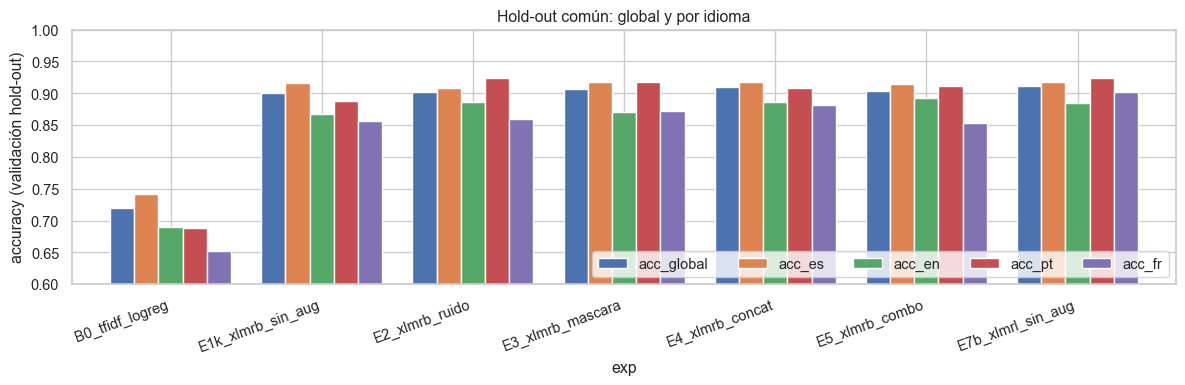

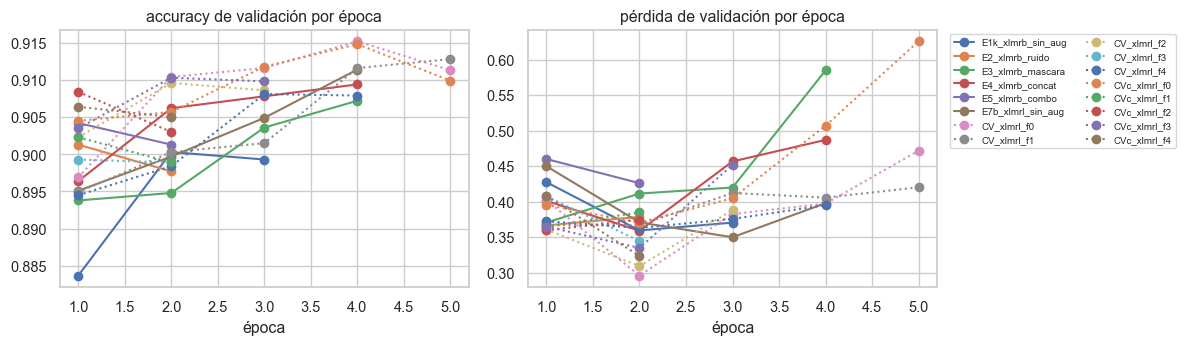

In [14]:
hold = reg[(reg.folds.fillna(0) == 0) & (reg.estado == "válido")]
ax = hold.set_index("exp")[["acc_global", "acc_es", "acc_en", "acc_pt", "acc_fr"]].plot.bar(figsize=(12, 4), width=0.8)
ax.set_ylim(0.6, 1); ax.set_ylabel("accuracy (validación hold-out)"); ax.set_title("Hold-out común: global y por idioma"); ax.legend(ncol=5, loc="lower right"); plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for _, r in reg[(reg.estado == "válido") & (reg.exp != "B0_tfidf_logreg")].iterrows():   # el reentrenamiento (F) se compara en la sección 12
    h = pd.DataFrame(json.loads(r.historial))
    if len(h) > 1:
        ls = "-" if r.folds == 0 else ":"; ax[0].plot(h.epoch, h.acc_val, ls, marker="o", label=r.exp); ax[1].plot(h.epoch, h.loss_val, ls, marker="o", label=r.exp)
ax[0].set_title("accuracy de validación por época"); ax[1].set_title("pérdida de validación por época"); ax[0].set_xlabel("época"); ax[1].set_xlabel("época")
ax[1].legend(fontsize=7, ncol=2, bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

In [15]:
def oof(prefijo):
    """Predicciones out-of-fold (probabilidades) de los 5 folds de una configuración, indexadas por id."""
    partes = []
    for k in range(5):
        d = pd.read_csv(OUT / f"val_pred_{prefijo}_f{k}.csv"); d[LABELS] = softmax(np.load(OUT / f"val_logits_{prefijo}_f{k}.npy"), -1); d["fold"] = k
        partes.append(d)
    return pd.concat(partes).set_index("id").sort_index()
C, D = oof("CV_xlmrl"), oof("CVc_xlmrl")
assert (C.index == D.index).all() and (C.fold == D.fold).all() and len(C) == len(train)
y = C.label.map(L2I).values
pC, pD = C[LABELS].values, D[LABELS].values; pCD = (pC + pD) / 2
acc = lambda p, m=slice(None): float((p[m].argmax(1) == y[m]).mean())
tabla_cv = pd.DataFrame({f"fold {k}": {"C: large sin aug": acc(pC, C.fold.values == k), "D: large + concat": acc(pD, C.fold.values == k),
                                       "ensamble C+D": acc(pCD, C.fold.values == k)} for k in range(5)})
tabla_cv["OOF (20.466)"] = [acc(pC), acc(pD), acc(pCD)]
display(tabla_cv.style.format("{:.4f}").background_gradient(axis=1, cmap="Greens"))

,fold 0,fold 1,fold 2,fold 3,fold 4,OOF (20.466)
C: large sin aug,0.9152,0.9128,0.9096,0.8993,0.9081,0.9090
D: large + concat,0.9148,0.9023,0.9084,0.9103,0.9064,0.9084
ensamble C+D,0.9145,0.9098,0.9172,0.9098,0.9098,0.9122


### 9.1 Historia de iteraciones y decisiones

| # | Iteración | Cambio respecto a la anterior | Resultado | Decisión |
|---|---|---|---|---|
| B0 | TF-IDF + regresión logística | — | 0,720 hold-out · **Kaggle 0,74361** (envío 01) | Referencia clásica; deja claro que hace falta modelar el orden |
| E1 | XLM-R base, 4 épocas, CPU local (8 h) | Encoder preentrenado en vez de n-gramas | El `Trainer` reportó 0,888, pero el CSV salió con 0,35 | **Inválido** (ver abajo). Corregimos el pipeline y añadimos controles |
| E1b | XLM-R base, 1 época (la mejor de E1), CPU | Menos épocas para caber en CPU | 0,890 (partición local) · **Kaggle 0,86149** (envío 02) | +12 puntos sobre B0. Pasamos a GPU de Kaggle |
| E1k | XLM-R base sin aumentación, Kaggle | Misma partición y configuración que E2–E5 | 0,900 (mejor época 2; paró en la 3) | Referencia pareada de la fase A |
| E2–E5 | XLM-R base + aumentación | Una técnica por experimento (y su combinación) | concat 0,909 > máscara 0,907 > combinación 0,904 > ruido 0,901 (todas ≥ E1k) | `concat` es la mejor técnica |
| E7b | XLM-R **large** sin aumentación | Encoder 2× más grande | 0,911 · **Kaggle 0,89587** (envío 03) | La capacidad ayuda más que la aumentación en *base* |
| Ens. | E7b + E4 (promedio de probabilidades) | Combinar el mejor *large* y la mejor aumentación | 0,915 · **Kaggle 0,89685** (envío 04) | El ensamble suma; conviene hacerlo con más modelos |
| C | Large sin aug., CV 5 folds | Usar todo `train` y promediar 5 modelos | OOF 0,909 · **Kaggle 0,90225** (envío 05) | Primer envío > 0,90 |
| D | Large + concat, mismos 5 folds | Aumentación sobre el modelo grande | OOF 0,908 (igual que C) | Sola no mejora, pero se equivoca en otros textos |
| C+D | Ensamble de 10 modelos | Promediar C y D | **OOF 0,912 · Kaggle 0,90324** (envío 06) | **Modelo final** |
| E | mDeBERTa-v3, 5 folds | Otra arquitectura para diversificar | Pérdida NaN desde el paso ≈100; exactitud 0,36 | Descartado |
| F | Reentrenamiento de C y D | Mismo código y semilla, guardando los pesos | OOF 0,913 (envío 07) | **Modelo entregado** (sección 12) |

**El error de E1 y cómo lo detectamos.** Con `group_by_length=True` (agrupar textos de longitud similar para acelerar), la versión 4.56 de
`transformers` también **reordena las filas en `predict()`** mediante un muestreo aleatorio por longitud. El `Trainer` calculaba bien su
exactitud (0,888), porque reordena etiquetas y predicciones a la vez, pero nuestras predicciones guardadas quedaban asignadas a otros
ids: la exactitud recalculada daba 0,35, que equivale al azar. El CSV de E1 nunca se envió. Quitamos `group_by_length` y añadimos un
`RuntimeError` si la exactitud recalculada difiere en más de 0,01 de la del `Trainer`. Desde entonces el control pasó en todos los experimentos.

**Diferencias de entorno documentadas.**
- E1/E1b corrieron en CPU local (transformers 4.56). El resto corrió en Kaggle (GPU T4, transformers 5.x).
- transformers 5 eliminó `warmup_ratio`. En E2–E5, E1k y E7b el calentamiento quedó en 0, porque el script filtra los argumentos no
  soportados y lo avisa. Desde la fase C se pasa como `warmup_steps` (6 % de los pasos). Por eso E1k se ejecutó sin calentamiento, igual
  que E2–E5, para que la comparación con/sin aumentación sea pareada.

**Por qué falló mDeBERTa (fase E).** La pérdida inicial fue 2,2, el doble de lo esperado (ln 3 ≈ 1,1), lo que apunta al reparto del lote
entre las dos GPU del kernel (*DataParallel*). La norma del gradiente pasó a NaN hacia el paso 100 y el modelo quedó prediciendo una sola
clase. Con el techo de la sección 11 a la vista, la mejora esperable del ensamble era de milésimas, menor que el ruido del leaderboard
público, así que no invertimos más GPU en depurarlo. Sus salidas (`*CVd_*`) no se usan en ningún ensamble.

## 10. Comparación con y sin aumentación de datos

Hacemos dos comparaciones, ambas **pareadas** (mismas particiones de validación, sin datos aumentados en la validación):

1. **XLM-R base, hold-out común (3.070 textos):** E1k (sin aumentación) frente a E2–E5.
2. **XLM-R large, validación cruzada (20.466 textos OOF):** fase C (sin aumentación) frente a fase D (concatenación), texto a texto, con
   prueba de McNemar sobre los textos en que discrepan.

In [16]:
ref = hold[hold.exp == "E1k_xlmrb_sin_aug"].iloc[0]
cmp_ = hold[hold.exp.isin(["E1k_xlmrb_sin_aug", "E2_xlmrb_ruido", "E3_xlmrb_mascara", "E4_xlmrb_concat", "E5_xlmrb_combo"])].copy()
for c in ["acc_global", "acc_es", "acc_en", "acc_pt", "acc_fr"]: cmp_[f"Δ{c[4:]}"] = (cmp_[c] - ref[c]).round(4)
display(cmp_[["exp", "aug", "n_train", "mejor_epoca", "acc_global"] + [c for c in cmp_.columns if c.startswith("Δ")]].style.format(precision=4)
        .background_gradient(subset=[c for c in cmp_.columns if c.startswith("Δ")], cmap="RdYlGn", vmin=-0.03, vmax=0.03))
def mcnemar(p_a, p_b, etiqueta):
    a, b = p_a.argmax(1) == y_ref, p_b.argmax(1) == y_ref
    n01, n10 = int((~a & b).sum()), int((a & ~b).sum())
    print(f"{etiqueta}: solo acierta A={n10} | solo acierta B={n01} | p-valor McNemar={binomtest(n01, n01 + n10).pvalue:.3g}")
va_ids = pd.read_csv(OUT / "val_pred_E1k_xlmrb_sin_aug.csv").id
def logits_hold(e):
    d = pd.read_csv(OUT / f"val_pred_{e}.csv"); d[LABELS] = softmax(np.load(OUT / f"val_logits_{e}.npy"), -1); return d.set_index("id").loc[va_ids]
H = {e: logits_hold(e) for e in ["E1k_xlmrb_sin_aug", "E2_xlmrb_ruido", "E3_xlmrb_mascara", "E4_xlmrb_concat", "E5_xlmrb_combo", "E7b_xlmrl_sin_aug"]}
y_ref = H["E1k_xlmrb_sin_aug"].label.map(L2I).values
for e in ["E2_xlmrb_ruido", "E3_xlmrb_mascara", "E4_xlmrb_concat", "E5_xlmrb_combo"]: mcnemar(H["E1k_xlmrb_sin_aug"][LABELS].values, H[e][LABELS].values, f"E1k vs {e}")

,exp,aug,n_train,mejor_epoca,acc_global,Δglobal,Δes,Δen,Δpt,Δfr
3,E1k_xlmrb_sin_aug,ninguna,17396,2.0000,0.9003,0.0000,0.0000,0.0000,0.0000,0.0000
4,E2_xlmrb_ruido,ruido,26094,1.0000,0.9013,0.0010,-0.0078,0.0198,0.0353,0.0032
5,E3_xlmrb_mascara,mascara,26094,4.0000,0.9072,0.0069,0.0024,0.0029,0.0294,0.0159
6,E4_xlmrb_concat,concat,26094,4.0000,0.9094,0.0091,0.0024,0.0198,0.0206,0.0255
7,E5_xlmrb_combo,ruido+mascara+concat,34616,1.0000,0.9042,0.0039,-0.0010,0.0255,0.0236,-0.0032


E1k vs E2_xlmrb_ruido: solo acierta A=119 | solo acierta B=122 | p-valor McNemar=0.898
E1k vs E3_xlmrb_mascara: solo acierta A=133 | solo acierta B=154 | p-valor McNemar=0.238
E1k vs E4_xlmrb_concat: solo acierta A=147 | solo acierta B=175 | p-valor McNemar=0.132
E1k vs E5_xlmrb_combo: solo acierta A=140 | solo acierta B=152 | p-valor McNemar=0.52


In [17]:
y_ref = y
mcnemar(pC, pD, "Large: C (sin aug) vs D (concat), OOF")
mcnemar(pC, pCD, "Large: C vs ensamble C+D, OOF")
por_idioma = pd.DataFrame({"C sin aug": pd.Series(pC.argmax(1) == y, index=C.index).groupby(C.lang).mean(),
                           "D concat": pd.Series(pD.argmax(1) == y, index=C.index).groupby(C.lang).mean(),
                           "C+D": pd.Series(pCD.argmax(1) == y, index=C.index).groupby(C.lang).mean()}).round(4)
por_idioma["n"] = C.lang.value_counts(); display(por_idioma.T)
print(f"acuerdo entre C y D: {(pC.argmax(1) == pD.argmax(1)).mean():.3f}")

Large: C (sin aug) vs D (concat), OOF: solo acierta A=852 | solo acierta B=840 | p-valor McNemar=0.789
Large: C vs ensamble C+D, OOF: solo acierta A=400 | solo acierta B=466 | p-valor McNemar=0.0271


lang,en,es,fr,mix,pt
C sin aug,0.8964,0.9164,0.8896,0.7670,0.9020
D concat,0.8875,0.9174,0.8910,0.7282,0.9003
C+D,0.8964,0.9183,0.9030,0.7379,0.9086
n,2356.0000,13649.0000,2092.0000,103.0000,2266.0000


acuerdo entre C y D: 0.917


**Lectura de resultados.**

- **En XLM-R base, las cuatro variantes con aumentación superan a la referencia sin aumentación** en la misma validación: ruido +0,1,
  combinación +0,4, máscara +0,7 y **concatenación +0,9 puntos**. La ganancia de `concat` se concentra donde se esperaba según su diseño:
  +2,0 puntos en inglés, +2,6 en francés y +2,1 en portugués, casi nada en español (que ya tenía muchos ejemplos). Produce textos largos y
  bilingües, parecidos a los de `eval`.
- **Con 3.070 textos de validación, ninguna de esas diferencias es estadísticamente significativa** (McNemar, p entre 0,13 y 0,90): los
  modelos discrepan en ≈300 textos, y la ventaja de `concat` es de 28 textos. Lo reportamos tal cual. Que las cuatro técnicas apunten en
  la misma dirección y que la ganancia aparezca justo en los idiomas con menos datos es evidencia consistente, pero no concluyente.
- **La aumentación actúa como regularizador.** Sin aumentación, el modelo alcanza su mejor época en la 2 y empeora en la 3 (*early
  stopping*). Con `mascara` y `concat` la exactitud sigue mejorando hasta la época 4: con más variedad de textos, el modelo tarda más en
  memorizar el conjunto de entrenamiento.
- **Combinar las tres técnicas (E5) no suma**: con 34.616 ejemplos, la mitad sintéticos, el modelo alcanza su mejor época en la primera,
  y el ruido de las técnicas más débiles diluye la señal de `concat`. Por eso en la fase D usamos solo `concat`.
- **En XLM-R large la aumentación por sí sola no mejora**: C y D empatan en OOF (0,909 frente a 0,908; p = 0,79). El modelo grande ya
  generaliza bien entre idiomas gracias a su preentrenamiento, y los textos sintéticos no le aportan información nueva.
- **Pero la aumentación sí aporta al modelo final**, a través de la diversidad: C y D coinciden en el 91,7 % de sus predicciones, y su
  ensamble mejora en **los cinco folds** (tabla de la sección 9) y de forma **significativa** en OOF (466 frente a 400 textos ganados;
  p = 0,027). Es una mejora estable, no un ajuste al leaderboard público: se mide sobre los 20.466 textos de `train` con modelos que no los vieron.

## 11. Análisis de errores y techo de desempeño

Analizamos los errores sobre las predicciones **out-of-fold del ensamble final** (C+D): son 20.466 predicciones, cada una hecha por modelos
que no vieron ese texto, mucho más estable que el hold-out de 3.070. Comparamos con el baseline clásico en el hold-out común.

lang,en,es,fr,mix,pt
n,2356.0000,13649.0000,2092.000,103.0000,2266.0000
accuracy,0.8964,0.9183,0.903,0.7379,0.9086


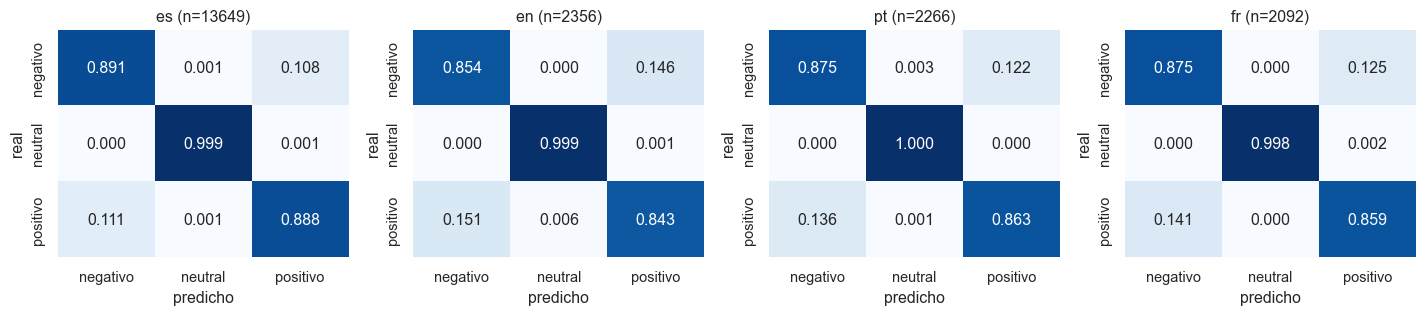

              precision    recall  f1-score   support

    negativo      0.876     0.884     0.880      7381
     neutral      0.997     0.999     0.998      5599
    positivo      0.884     0.875     0.880      7486

    accuracy                          0.912     20466
   macro avg      0.919     0.919     0.919     20466
weighted avg      0.912     0.912     0.912     20466



In [18]:
from sklearn.metrics import confusion_matrix, classification_report
E = C[["lang", "label"]].copy(); E["pred"] = np.array(LABELS)[pCD.argmax(1)]; E["conf"] = pCD.max(1); E["ok"] = E.label == E.pred
E["text"] = train.set_index("id").loc[E.index, "text"]
display(E.groupby("lang").agg(n=("ok", "size"), accuracy=("ok", "mean")).round(4).T)
langs = [l for l in ["es", "en", "pt", "fr"] if (E.lang == l).any()]
fig, axs = plt.subplots(1, len(langs), figsize=(3.6 * len(langs), 3.3))
for ax, l in zip(axs, langs):
    s = E[E.lang == l]
    sns.heatmap(confusion_matrix(s.label, s.pred, labels=LABELS, normalize="true"), annot=True, fmt=".3f", cmap="Blues", cbar=False,
                xticklabels=LABELS, yticklabels=LABELS, ax=ax); ax.set_title(f"{l} (n={len(s)})"); ax.set_xlabel("predicho"); ax.set_ylabel("real")
plt.tight_layout(); plt.show()
print(classification_report(E.label, E.pred, digits=3))

In [19]:
# Encoder vs bolsa de n-gramas por idioma, en el hold-out común
b0 = pd.read_csv(OUT / "val_pred_B0_tfidf_logreg.csv").set_index("id").loc[va_ids]
y_h =H["E1k_xlmrb_sin_aug"].label.map(L2I).values; lang_h = H["E1k_xlmrb_sin_aug"].lang
comp = pd.DataFrame({"B0 TF-IDF": pd.Series((b0.label == b0.pred).values, index=va_ids).groupby(lang_h.values).mean(),
                     "E1k XLM-R base": pd.Series(H["E1k_xlmrb_sin_aug"][LABELS].values.argmax(1) == y_h).groupby(lang_h.values).mean(),
                     "E4 base + concat": pd.Series(H["E4_xlmrb_concat"][LABELS].values.argmax(1) == y_h).groupby(lang_h.values).mean(),
                     "E7b XLM-R large": pd.Series(H["E7b_xlmrl_sin_aug"][LABELS].values.argmax(1) == y_h).groupby(lang_h.values).mean()}).round(4)
comp.loc["global"] = [(b0.label == b0.pred).mean()] + [float((H[e][LABELS].values.argmax(1) == y_h).mean()) for e in ["E1k_xlmrb_sin_aug", "E4_xlmrb_concat", "E7b_xlmrl_sin_aug"]]
display(comp.T.round(4))

,en,es,fr,mix,pt,global
B0 TF-IDF,0.6893,0.7411,0.6529,0.6000,0.6882,0.7195
E1k XLM-R base,0.8672,0.9155,0.8567,0.8000,0.8882,0.9003
E4 base + concat,0.8870,0.9179,0.8822,0.8667,0.9088,0.9094
E7b XLM-R large,0.8842,0.9170,0.9013,0.7333,0.9235,0.9114


In [20]:
# ¿Dónde están los errores? Exactitud del ensamble según su confianza (probabilidad de la clase predicha)
cortes = [0, .6, .7, .8, .9, .95, .99, 1]
t = E.groupby(pd.cut(E.conf, cortes), observed=True).agg(n=("ok", "size"), accuracy=("ok", "mean"))
t["% de train"] = (t.n / len(E) * 100).round(1); display(t.round(3).T)
print(pd.crosstab(E.label, E.pred, margins=True))

conf,"(0.0, 0.6]","(0.6, 0.7]","(0.7, 0.8]","(0.8, 0.9]","(0.9, 0.95]","(0.95, 0.99]","(0.99, 1.0]"
n,2053.000,793.000,594.000,407.00,262.000,1033.000,15324.000
accuracy,0.547,0.549,0.604,0.72,0.828,0.936,0.997
% de train,10.000,3.900,2.900,2.00,1.300,5.000,74.900


pred      negativo  neutral  positivo    All
label                                       
negativo      6523        6       852   7381
neutral          0     5595         4   5599
positivo       925        9      6552   7486
All           7448     5610      7408  20466


In [21]:
# Muestra de errores del ensamble (reseñas mixtas)
for lab in ["positivo", "negativo"]:
    for _, r in E[(~E.ok) & (E.label == lab) & (E.lang == "es")].sample(4, random_state=3).iterrows():
        print(f"[real={r.label} pred={r.pred} conf={r.conf:.2f}] {r.text[:330]}\n")

[real=positivo pred=negativo conf=0.51] Me llego el paquete un martes por la tarde, como dos dias despues de pedirlo, y lo traje para la oficina donde lo tengo en el escritorio. Termine feliz con el cargador. La camara se dano antes de lo que esperaba, y eso que apenas llevaba unas semanas con el aaprato, comprado a mediados de ano. La verdad es que tengo sentimientos

[real=positivo pred=negativo conf=0.53] Me llegó el lunes pasado, lo compré en línea y tardó tres días en llegar. La resolución me sorprendió para bien, la uso sobre todo en las noches en la sala de mi depto. La tapa le pondría una estrella, nomás no me convence como está. Ahi lo dejo, a ver con el tiempo.

[real=positivo pred=negativo conf=0.65] Lo compré hace poco por internet y llegó en unos días, la verdad sin demoras. Está funcionando sin parar desde que la instalé, la tengo prendida casi todo el día en la sala. El manual de uso vale totalmente la pena, lo hojeé completo antes de empezar. Eso sí, la terminación fue 

In [22]:
# Techo de desempeño: ¿hay señal aprendible en las reseñas donde el ensamble duda?
from sklearn.model_selection import cross_val_score
dificil = E[(E.conf < 0.9) & (E.label != "neutral")]
pipe = lambda: make_pipeline(make_union(TfidfVectorizer(ngram_range=(1, 3), sublinear_tf=True, min_df=2),
                                        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2)),
                             LogisticRegression(C=5, max_iter=2000))
acc_dificil = cross_val_score(pipe(), dificil.text, dificil.label, cv=5).mean()
facil = E[E.conf >= 0.9]
print(f"grupo difícil (confianza < 0,9, pos/neg): {len(dificil)} textos = {len(dificil)/len(E):.1%} de train | etiquetas: {dificil.label.value_counts(normalize=True).round(3).to_dict()}")
print(f"  exactitud del ensamble ahí: {dificil.ok.mean():.3f} | TF-IDF entrenado SOLO con ese grupo (CV5): {acc_dificil:.3f}")
print(f"grupo fácil (confianza ≥ 0,9): {len(facil)/len(E):.1%} de train, exactitud {facil.ok.mean():.4f}")
techo = (len(facil) * facil.ok.mean() + (len(E) - len(facil)) * 0.5) / len(E)
print(f"exactitud esperada si el grupo difícil fuera irreducible (50 %): {techo:.4f} | ensamble OOF: {E.ok.mean():.4f}")

grupo difícil (confianza < 0,9, pos/neg): 3840 textos = 18.8% de train | etiquetas: {'positivo': 0.501, 'negativo': 0.499}
  exactitud del ensamble ahí: 0.574 | TF-IDF entrenado SOLO con ese grupo (CV5): 0.498
grupo fácil (confianza ≥ 0,9): 81.2% de train, exactitud 0.9905
exactitud esperada si el grupo difícil fuera irreducible (50 %): 0.8983 | ensamble OOF: 0.9122


**Observaciones.**

- **El neutral está resuelto**: prácticamente todos los errores son confusiones `negativo` ↔ `positivo` (matrices y tabla cruzada). El
  modelo distingue sin problema una reseña tibia de una con opinión.
- **Todos los errores se concentran en un grupo concreto.** Las predicciones con confianza ≥ 0,99 (≈75 % de `train`) aciertan el 99,7 %.
  Los errores están en las predicciones con confianza baja: reseñas de plantilla que combinan un elogio y una queja ("me decepcionó la
  calidad… por otro lado, la portabilidad es justo lo que buscaba") y cierran sin veredicto ("lo dejo a tu criterio", "sopésalo tú mismo").
- **Ese grupo parece casi irreducible.** Son 3.840 textos (18,8 % de `train`), con etiquetas repartidas 50/50 entre positivo y negativo. El
  ensamble acierta ahí el 57 %, y un clasificador entrenado *solo* con esos textos no supera el azar (0,498). Para un lector humano tampoco
  hay una regla clara que decida la etiqueta. Si ese grupo fuera puro azar, la exactitud esperada sería 0,898; el ensamble llega a 0,912
  porque extrae algo de señal, pero el margen restante es pequeño: el techo práctico está en torno a 0,91–0,92.
- **Frente al baseline clásico**, el encoder gana entre 17 y 20 puntos en todos los idiomas, y más en francés y portugués (+20): la
  representación multilingüe compartida transfiere lo aprendido con el español, mientras que los n-gramas de cada idioma tienen pocos ejemplos.
- Por idioma, el ensamble va de 0,896 (inglés) y 0,903 (francés) a 0,918 (español). Los idiomas con menos datos siguen siendo los más
  difíciles, pero la brecha es mucho menor que con TF-IDF (2 frente a 9 puntos).

**Implicación para el modelo final.** Seguir subiendo la exactitud con modelos más complejos tiene poco margen y alto riesgo de sobreajustar
al leaderboard público: con ≈2.000 textos en el puntaje público, una diferencia de 0,001 son 2 reseñas. Por eso elegimos el modelo final
con la validación cruzada, no con el puntaje público.

## 12. Modelo final y envíos a Kaggle

**Modelo final:** promedio de las probabilidades (*softmax*) de **10 modelos XLM-RoBERTa-large**: los 5 de la fase C (sin aumentación) y
los 5 de la fase D (concatenación), entrenados sobre los mismos 5 folds. La clase predicha es la de mayor probabilidad media; no hay
pesos ni umbrales ajustados. Ninguna decisión se tomó mirando el puntaje público.

**Por qué esta configuración:**
1. Es la mejor en validación cruzada: OOF 0,912 y mejora en los 5 folds respecto a cada mitad por separado.
2. Cada modelo ve el 80 % de `train`; entre los 5 folds se usa el 100 % de los datos.
3. Promediar modelos reduce la varianza: el mismo modelo con otro fold de validación oscila entre 0,899 y 0,915.
4. Combina la capacidad del modelo grande con la diversidad que aporta la aumentación.

La celda siguiente regenera el envío final a partir de los logits guardados y comprueba que es idéntico al archivo enviado.

In [23]:
def generar_envio(prob, nombre):
    sub = pd.DataFrame({"id": eval_df.id, "answer": np.array(LABELS)[np.asarray(prob).argmax(-1)]})
    assert list(sub.columns) == list(sample.columns) and len(sub) == len(sample) and (sub.id.values == sample.id.values).all() and sub.answer.isin(LABELS).all()
    return sub
FINAL = [f"CV_xlmrl_f{k}" for k in range(5)] + [f"CVc_xlmrl_f{k}" for k in range(5)]
P_eval = np.mean([softmax(np.load(OUT / f"eval_logits_{e}.npy"), -1) for e in FINAL], axis=0)
sub = generar_envio(P_eval, "final")
enviado = pd.read_csv("envios/submission_06_ens_CV10_xlmrl_noaug_concat.csv")
print("idéntico al envío 06:", sub.equals(enviado), "| distribución:", sub.answer.value_counts(normalize=True).round(3).to_dict())
print("idiomas en eval:", eval_df.lang.value_counts(normalize=True).round(3).to_dict())

idéntico al envío 06: True | distribución: {'positivo': 0.413, 'negativo': 0.395, 'neutral': 0.192}
idiomas en eval: {'es': 0.602, 'en': 0.137, 'pt': 0.134, 'fr': 0.119, 'mix': 0.008}


### 12.1 Reentrenamiento con pesos guardados: el modelo entregado

Las corridas C y D se hicieron sin guardar los pesos: con 3 modelos *large* por kernel, los pesos y los *checkpoints* superaban los
20 GB de disco de Kaggle. Para el entregable reentrenamos los mismos 10 modelos (fase F): mismo código, misma semilla y mismos folds,
con dos cambios que no afectan el entrenamiento. Los *checkpoints* intermedios guardan solo los pesos (`save_only_model`), y cada modelo
final se guarda con `save_pretrained`. Corrió en la cuenta de Kaggle de otro integrante, para usar su cuota de GPU.

Las GPU no son deterministas bit a bit, así que los modelos nuevos no son idénticos a los originales: en varios folds el *early
stopping* se detuvo en otra época. La tabla compara ambas versiones sobre las mismas predicciones *out-of-fold*.

In [24]:
Cr, Dr = oof("CVr_xlmrl"), oof("CVcr_xlmrl")
assert (Cr.index == C.index).all() and (Cr.fold == C.fold).all() and (Dr.index == C.index).all()
pCDr = (Cr[LABELS].values + Dr[LABELS].values) / 2
comp_r = pd.DataFrame({f"fold {k}": {"original (envío 06)": acc(pCD, C.fold.values == k), "reentrenado (envío 07)": acc(pCDr, C.fold.values == k)} for k in range(5)})
comp_r["OOF (20.466)"] = [acc(pCD), acc(pCDr)]
display(comp_r.style.format("{:.4f}").background_gradient(axis=1, cmap="Greens"))
mcnemar(pCD, pCDr, "original vs reentrenado, OOF")
FINAL_R = [f"CVr_xlmrl_f{k}" for k in range(5)] + [f"CVcr_xlmrl_f{k}" for k in range(5)]
P_eval_r = np.mean([softmax(np.load(OUT / f"eval_logits_{e}.npy"), -1) for e in FINAL_R], axis=0)
sub_r = generar_envio(P_eval_r, "entregado")
enviado_07 = pd.read_csv("envios/submission_07_ens_CV10_reentrenado.csv")
print("idéntico al envío 07:", sub_r.equals(enviado_07), f"| coincidencia con el envío 06: {(sub_r.answer == enviado.answer).mean():.3f}")

,fold 0,fold 1,fold 2,fold 3,fold 4,OOF (20.466)
original (envío 06),0.9145,0.9098,0.9172,0.9098,0.9098,0.9122
reentrenado (envío 07),0.9126,0.9118,0.9142,0.9157,0.9128,0.9134


original vs reentrenado, OOF: solo acierta A=521 | solo acierta B=545 | p-valor McNemar=0.481
idéntico al envío 07: True | coincidencia con el envío 06: 0.963


**Lectura.** El ensamble reentrenado es equivalente al original: OOF 0,913 frente a 0,912, sin diferencia significativa (McNemar), y algo
más parejo entre folds. Sus predicciones sobre `eval` coinciden en un 96 % con el envío 06. Las discrepancias se concentran en las reseñas
mixtas de la sección 11, donde los modelos dudan y una variación pequeña cambia la clase. Lo enviamos a Kaggle como envío 07 para que el
modelo entregado tenga su propio puntaje público.

**Puntaje público del envío 07: 0,89833, frente a 0,90324 del 06.** La diferencia (0,0049) equivale a unas 10 reseñas del subconjunto
público (≈30 % de `eval`). Los dos ensambles discrepan en ≈250 textos de `eval` (≈75 en la parte pública), casi todos del grupo de
reseñas mixtas donde ningún modelo supera mucho el azar. Que uno acierte unas 10 más que el otro es compatible con el azar, y la
validación cruzada, con 10 veces más textos, no muestra diferencia (0,913 frente a 0,912). Por eso no lo leemos como un modelo peor y
seleccionamos los dos para el leaderboard privado, que se calcula con el ≈70 % restante de `eval`.

#,archivo,modelo / cambio,validación,Kaggle público
01,submission_01_B0_tfidf_logreg,TF-IDF + regresión logística (baseline clásico),"0,720 (hold-out)",0.74361
02,submission_02_E1b_xlmrb_1ep,"XLM-R base sin aumentación, 1 época (CPU)","0,890 (hold-out local)",0.86149
03,submission_03_E7b_xlmrl_sin_aug,XLM-R large sin aumentación,"0,911 (hold-out)",0.89587
04,submission_04_ens_E7b_E4,Ensamble E7b (large) + E4 (base + concat),"0,915 (hold-out)",0.89685
05,submission_05_ens_CV5_xlmrl,Ensamble 5 folds XLM-R large sin aumentación,"0,909 (OOF por modelo)",0.90225
06,submission_06_ens_CV10_xlmrl_noaug_concat,Ensamble 10 modelos: 5 sin aug + 5 con concat,"0,912 (OOF)",0.90324
07,submission_07_ens_CV10_reentrenado,Mismo ensamble reentrenado con pesos guardados ← MODELO ENTREGADO,"0,913 (OOF)",0.89833


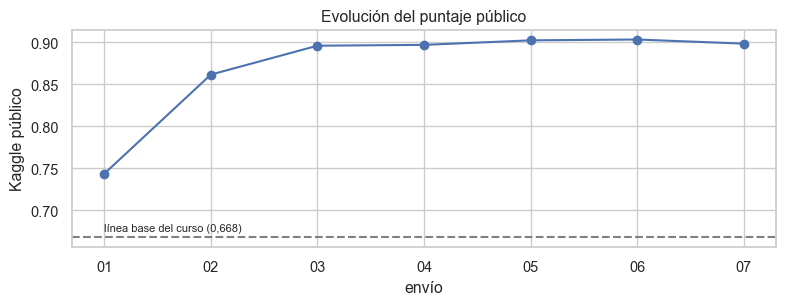

In [25]:
PUNTAJE_07 = 0.89833   # puntaje público del envío 07
envios = pd.DataFrame([
    ("01", "submission_01_B0_tfidf_logreg", "TF-IDF + regresión logística (baseline clásico)", "0,720 (hold-out)", 0.74361),
    ("02", "submission_02_E1b_xlmrb_1ep", "XLM-R base sin aumentación, 1 época (CPU)", "0,890 (hold-out local)", 0.86149),
    ("03", "submission_03_E7b_xlmrl_sin_aug", "XLM-R large sin aumentación", "0,911 (hold-out)", 0.89587),
    ("04", "submission_04_ens_E7b_E4", "Ensamble E7b (large) + E4 (base + concat)", "0,915 (hold-out)", 0.89685),
    ("05", "submission_05_ens_CV5_xlmrl", "Ensamble 5 folds XLM-R large sin aumentación", "0,909 (OOF por modelo)", 0.90225),
    ("06", "submission_06_ens_CV10_xlmrl_noaug_concat", "Ensamble 10 modelos: 5 sin aug + 5 con concat", "0,912 (OOF)", 0.90324),
    ("07", "submission_07_ens_CV10_reentrenado", "Mismo ensamble reentrenado con pesos guardados  ← MODELO ENTREGADO", "0,913 (OOF)", PUNTAJE_07),
], columns=["#", "archivo", "modelo / cambio", "validación", "Kaggle público"])
display(envios.style.hide(axis="index").format(na_rep="pendiente", precision=5).bar(subset=["Kaggle público"], vmin=0.7, vmax=0.91, color="#8fd18f"))
fig, ax = plt.subplots(figsize=(8, 3.2)); ax.plot(envios["#"], envios["Kaggle público"], marker="o")
ax.axhline(0.668, ls="--", c="gray"); ax.text(0, 0.675, "línea base del curso (0,668)", fontsize=8)
ax.set_ylabel("Kaggle público"); ax.set_xlabel("envío"); ax.set_title("Evolución del puntaje público"); plt.tight_layout(); plt.show()

**Lectura.**
- Los envíos 01–06 corresponden cada uno a una iteración de la sección 9 y **todos mejoran el anterior**, desde 0,744 hasta 0,903. El 07
  no es una iteración nueva: es el mismo modelo que el 06, reentrenado para poder entregar sus pesos.
- Todos superan la línea base del curso (0,668); el final la supera por 23,5 puntos.
- La distancia entre validación y Kaggle se reduce a medida que el modelo se vuelve más robusto: 2,8 puntos en el envío 02 y 0,9 en el 06.
  Es lo contrario de lo que pasaría con sobreajuste.
- Con el envío 06 el equipo quedó **empatado en el primer puesto del leaderboard público** al 17-nov-2026, por encima del percentil 75.
- Para el leaderboard privado seleccionamos los envíos **06 y 07**: el mejor puntaje público y el modelo entregado, los dos mejores en
  validación cruzada.

## 13. Replicabilidad y modelo entregado

- **Código.** Todo el entrenamiento sale de `src/p2_train.py` con `SEED = 42`. `python src/kaggle_run.py <slug> <EXP…>` lo empaqueta como
  kernel de Kaggle con GPU, y `python src/kaggle_pull.py <slug>` descarga sus salidas y actualiza `registro_experimentos.csv`. El modelo
  final se reproduce con los experimentos `CV_xlmrl_f0…f4` y `CVc_xlmrl_f0…f4` y la opción `--guardar-modelo` (≈15 h de GPU T4 en
  total, en dos kernels de 5 modelos cada uno).
- **Particiones.** Son deterministas (sección 5) y este notebook verifica que coinciden con las usadas en Kaggle.
- **Envíos.** La sección 12 regenera los envíos 06 y 07 bit a bit a partir de los logits guardados en `salidas/`.
- **Modelo entregado.** Los 10 modelos del ensamble (fase F) están guardados con `save_pretrained` de Hugging Face (pesos `safetensors`
  + configuración + tokenizador; 2,24 GB cada uno) en dos datasets de Kaggle:
  [pesos-p2-final-c](https://www.kaggle.com/datasets/nicolasdavidvalentin/pesos-p2-final-c) (`modelos/CV_xlmrl_f0…f4`, sin aumentación) y
  [pesos-p2-final-d](https://www.kaggle.com/datasets/nicolasdavidvalentin/pesos-p2-final-d) (`modelos/CVc_xlmrl_f0…f4`, con concatenación).
  Se cargan con `AutoModelForSequenceClassification.from_pretrained(<carpeta>)`.

La celda siguiente busca los modelos en los datasets (si el notebook corre en Kaggle con ambos datasets añadidos) o en
`modelos/modelo_final/` (si se descargaron), predice 100 textos de `eval` con el ensamble y los compara con el envío 07.

In [26]:
def cargar_y_predecir(ruta, textos, max_len=192, bs=64):
    tok = AutoTokenizer.from_pretrained(ruta); m = AutoModelForSequenceClassification.from_pretrained(ruta).eval()
    dev = "cuda" if torch.cuda.is_available() else "cpu"; m.to(dev); out = []
    for i in range(0, len(textos), bs):
        b = tok(list(textos[i:i+bs]), truncation=True, max_length=max_len, padding=True, return_tensors="pt").to(dev)
        with torch.no_grad(): out.append(m(**b).logits.float().cpu().numpy())
    return np.concatenate(out)

CARPETAS = [f"CV_xlmrl_f{k}" for k in range(5)] + [f"CVc_xlmrl_f{k}" for k in range(5)]   # nombres dentro de los datasets
BASES = [Path("/kaggle/input/pesos-p2-final-c/modelos"), Path("/kaggle/input/pesos-p2-final-d/modelos"), Path("modelos/modelo_final")]
def buscar(carpeta):
    return next((b / carpeta for b in BASES if (b / carpeta / "config.json").exists()), None)
rutas_ok = [r for r in map(buscar, CARPETAS) if r is not None]
if len(rutas_ok) == len(CARPETAS):
    muestra = eval_df.sample(100, random_state=0)
    p = np.mean([softmax(cargar_y_predecir(r, muestra.text.tolist()), -1) for r in rutas_ok], axis=0)
    ref = enviado_07.set_index("id").loc[muestra.id, "answer"].values
    print("coincidencia con el envío 07 en 100 textos de eval:", np.mean(np.array(LABELS)[p.argmax(1)] == ref))
else:
    print(f"Modelos encontrados: {len(rutas_ok)} de {len(CARPETAS)}. Añade los datasets pesos-p2-final-c y pesos-p2-final-d "
          "(o descárgalos en modelos/modelo_final/) para ejecutar esta verificación.")

Modelos encontrados: 0 de 10. Añade los datasets pesos-p2-final-c y pesos-p2-final-d (o descárgalos en modelos/modelo_final/) para ejecutar esta verificación.


**Verificación ejecutada en Kaggle (22-nov-2026).** Corrimos esta comprobación en un kernel de Kaggle con GPU y los dos datasets de pesos
añadidos (`kat3016/p2-verif-pesos`). Los 10 modelos se cargaron desde disco y, sobre 100 textos de `eval`, cada uno predijo la misma
clase que sus logits guardados en el 100 % de los casos (diferencia máxima de logit: 0,0001). El ensamble coincidió con el envío 07 en
el 100 % de los textos. Los pesos publicados son, por tanto, exactamente los que generaron el envío 07.

## 14. Referencias, datos externos y uso de IA generativa

**Modelos preentrenados** (todos *encoder-only*; sobre sus representaciones se entrena una cabeza de clasificación):

| Modelo | Uso | Fuente | Licencia | Referencia |
|---|---|---|---|---|
| `FacebookAI/xlm-roberta-base` | Fase A (E1–E5) | https://huggingface.co/FacebookAI/xlm-roberta-base | MIT | Conneau et al. (2020). *Unsupervised Cross-lingual Representation Learning at Scale*. ACL |
| `FacebookAI/xlm-roberta-large` | Fases B–D y modelo final | https://huggingface.co/FacebookAI/xlm-roberta-large | MIT | Ídem |
| `microsoft/mdeberta-v3-base` | Fase E (falló; no forma parte del modelo final) | https://huggingface.co/microsoft/mdeberta-v3-base | MIT | He, Gao & Chen (2021). *DeBERTaV3*. ICLR 2023 |

**Datos externos:** no se usaron. Todo el entrenamiento proviene de `train.csv` de la competencia. Los datos sintéticos se construyen
exclusivamente a partir de la partición de entrenamiento con las transformaciones de la sección 7, sin ningún modelo.

**Software:** PyTorch, Hugging Face `transformers`, scikit-learn, SciPy, pandas, matplotlib/seaborn. Cómputo: kernels de Kaggle (GPU T4).

**Otras referencias:** Vaswani et al. (2017), *Attention Is All You Need*, NeurIPS · Devlin et al. (2019), *BERT*, NAACL · Liu et al.
(2019), *RoBERTa* · Wei & Zou (2019), *EDA: Easy Data Augmentation Techniques for Boosting Performance on Text Classification Tasks*, EMNLP.

### Uso de IA generativa en el desarrollo del proyecto

**Herramienta.** Claude (Anthropic), usado como asistente de programación a través de Claude Code (extensión de VS Code).

**Alcance: herramienta de desarrollo, no parte del modelo.** La IA generativa se usó solo para apoyar la escritura y revisión del
código y de la documentación. Ningún modelo generativo forma parte de la solución entregada: no generó ni tradujo textos de
entrenamiento (la aumentación de la sección 7 es determinista y sin modelos), no etiquetó ni procesó `eval.csv`, y ninguna de sus
salidas entra al entrenamiento ni a los envíos. Las predicciones provienen exclusivamente de los encoders XLM-R ajustados por el equipo.

Se usó en tres momentos del proyecto:

1. **Esqueleto inicial.** A partir del enunciado, la IA propuso la estructura del repositorio (`src/`, `salidas/`, `envios/`,
   `registro_experimentos.csv`), el índice de secciones del notebook alineado con los entregables (evidencia de iteración, comparación
   con/sin aumentación, referencias) y una primera versión de los scripts: el ciclo de *fine-tuning* con el `Trainer` de Hugging Face
   (`src/p2_train.py`), el lanzamiento y la descarga de kernels de Kaggle (`src/kaggle_run.py`, `src/kaggle_pull.py`) y la generación del
   notebook (`src/build_notebook.py`). Sobre ese esqueleto el equipo definió y ajustó los experimentos, los hiperparámetros, las técnicas
   de aumentación y el ensamble final.
2. **Detección y corrección de errores.** Se le entregaron trazas, *logs* y métricas para diagnosticar fallos. Los casos principales:
   - Predicciones desalineadas en E1: `group_by_length=True` reordenaba la salida de `predict()` en transformers 4.56, de modo que el CSV
     no correspondía a los `id`. Se detectó al comparar la exactitud reportada por el `Trainer` con la recalculada desde los logits
     guardados; desde entonces esa comprobación se hace en cada experimento.
   - Diferencias de entorno con Kaggle: transformers 5.x no acepta `group_by_length`, y Kaggle leía el script como latin-1, lo que
     cambiaba la detección de idioma en 76 textos (0,4 %) y con ello las particiones. Se ajustó el código para reproducir las mismas
     particiones en ambos entornos.
   - Fallo de `kaggle kernels output` (v1.7.4) con kernels que generan archivos, resuelto con un descargador propio en `kaggle_pull.py`.
   - Pérdida NaN de mDeBERTa (fase E): ayudó a descartar causas, pero el entrenamiento no se estabilizó y el modelo se excluyó del ensamble.
3. **Revisión final.** Se usó para contrastar el notebook, el `README` y este documento con el enunciado y la rúbrica (entregables,
   requisitos técnicos, referencias y licencias), verificar que las cifras coincidieran entre el notebook, `registro_experimentos.csv`
   y los envíos, comprobar que el notebook se ejecutara sin errores y corregir redacción y ortografía.

**Verificación y responsabilidad.** Cada sugerencia se revisó y se ejecutó antes de incorporarla, y las que no aplicaban se descartaron.
Todas las cifras reportadas provienen de nuestras propias ejecuciones (`salidas/`, `registro_experimentos.csv`, leaderboard de Kaggle)
y no de la IA. El equipo entiende el código entregado, responde por él y por las decisiones del proyecto, y puede sustentarlo.

## 15. Conclusiones

1. **El aprendizaje profundo resuelve lo que la bolsa de palabras no alcanza.** Un encoder multilingüe preentrenado sube de 0,720 (TF-IDF) a
   0,900 en la misma validación, porque representa cada palabra en su contexto (orden, negaciones, conectores) y comparte lo
   aprendido entre idiomas. En Kaggle: de 0,744 a 0,861 con XLM-R base y a 0,896 con XLM-R large.
2. **La aumentación sin modelos generativos ayuda, sobre todo como fuente de diversidad.** Con XLM-R base todas las técnicas superan a la
   referencia en la misma validación; la concatenación bilingüe es la mejor (+0,9 puntos; +2 a +2,6 en inglés, francés y portugués), aunque
   con 3.070 textos la diferencia no es significativa. En el modelo grande no mejora por sí sola, pero su ensamble con el modelo sin
   aumentación mejora en los cinco folds y de forma significativa en OOF.
3. **La validación cruzada fue la herramienta clave contra el sobreajuste.** Con 20.466 predicciones OOF, las decisiones (modelo, ensamble)
   se tomaron con una estimación estable, y el puntaje público siguió a la validación en cada envío: 0,903 con el modelo final.
4. **El margen restante es pequeño.** El ≈19 % de reseñas mixtas con cierre indeciso tiene etiquetas casi aleatorias entre positivo y negativo;
   ningún modelo (ni el ensamble ni un clasificador dedicado) supera ahí el azar, lo que sitúa el techo práctico en ≈0,91–0,92.
5. **Lecciones de proceso:** verificar que las predicciones guardadas reproducen la métrica del `Trainer` (lo que detectó el error de E1),
   comparar siempre sobre la misma partición, y documentar las diferencias de entorno (versiones de librerías, codificación del script).